FS score

In [ ]:
from scipy.io import loadmat

# Load the .mat file
mat_data = loadmat('paraIDM.mat')

# Print the keys in the mat_data
print(mat_data.keys())


dict_keys(['__header__', '__version__', '__globals__', 'paraIDM'])


In [9]:
import numpy as np

# Extract data using the 'paraIDM' key
data_array = np.array(mat_data['paraIDM'])

print(data_array.shape)


(1097, 6)


In [ ]:
import numpy as np
from scipy.spatial.distance import pdist, squareform
from sklearn.neighbors import kneighbors_graph
from scipy.io import loadmat
import pandas as pd

data = pd.read_csv('IDM_cali_params_list.csv')
data = (data - data.mean()) / data.std()
data = np.array(data)

def construct_weight_matrix(X, metric='euclidean', t=1.0, neighbor_num=5):
    pairwise_dists = squareform(pdist(X, metric))
    W = np.exp(-pairwise_dists ** 2 / t ** 2)
    # Set entries not belonging to k nearest neighbors to zero
    W = np.multiply(W, kneighbors_graph(X, neighbor_num, mode='connectivity', include_self=True).toarray())
    return W

def laplacian_score(X, W):
    # Degree matrix
    D = np.diag(np.sum(W, axis=1))
    
    # Laplacian matrix
    L = D - W
    
    # Compute the Laplacian score for each feature
    scores = []
    for i in range(X.shape[1]):
        fi = X[:, i]
        fi = fi - np.dot(D, fi).sum() / D.sum()
        L_score = np.dot(fi.T, np.dot(L, fi)) / np.dot(fi.T, np.dot(D, fi))
        scores.append(L_score)
    
    return np.array(scores)

# Step 1: Construct the similarity graph (using t=1.0 and 5 nearest neighbors for this example)
W = construct_weight_matrix(data, t=1.0, neighbor_num=5)

# Step 2: Compute the Laplacian Score
scores = laplacian_score(data, W)

# Rank features
sorted_indices = scores.argsort()  # sort in ascending order because lower score is better
top_features = sorted_indices[:2]  # take top 2 features

print(f"Top 2 important features based on Laplacian Score: {top_features}")


Top 2 important features based on Laplacian Score: [3 0]


In [ ]:
data = pd.read_csv('IDM_cali_params_list.csv')
data

,v0,a,b,s0,T
0,45.806605,2.623522,2.356663,4.878831,2.589121
1,36.767584,2.560798,3.124616,2.542668,1.937541
2,23.008855,2.814555,2.329792,3.962205,1.623674
3,40.726248,1.033256,3.820571,8.349283,0.745943
4,38.802017,1.023236,2.545102,4.795853,1.104039
...,...,...,...,...,...
1995,44.470769,0.285285,3.742939,2.778716,1.428289
1996,49.144644,3.074248,1.729454,5.562192,2.541532
1997,38.325666,0.849108,3.733822,5.669954,1.806014
1998,43.458616,2.787044,0.531794,5.785836,0.629173


PCA

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
import pandas as pd

df = pd.read_csv('Highd_IDM_para.csv')
data = (df - df.mean()) / df.std()
pca = PCA()
pca.fit(data)

# Determine how many principal components to retain for cumulative explained variance > 80%
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
num_components = np.where(cumulative_variance > 0.8)[0][0] + 1  # +1 since Python uses 0-based indexing

# Extract relevant loading scores and explained variances
selected_loading_scores = pca.components_[:num_components]
selected_variance = pca.explained_variance_ratio_[:num_components]

# Calculate the final score for each variable
variable_scores = np.dot(selected_variance, np.abs(selected_loading_scores))

# Rank variables based on these scores
ranked_indices = np.argsort(variable_scores)[::-1]  # Descending order
ranked_variables = [(index, variable_scores[index]) for index in ranked_indices]

# Display ranked variables
for rank, (index, score) in enumerate(ranked_variables, 1):
    print(f"Rank {rank} -> Variable {index}: {score}")


Rank 1 -> Variable 2: 0.36321308865458385
Rank 2 -> Variable 0: 0.32705804419438234
Rank 3 -> Variable 3: 0.3252214357957308
Rank 4 -> Variable 1: 0.24297190115168377
Rank 5 -> Variable 4: 0.23421436092132908


In [ ]:
# Select labels
import numpy as np
import pandas as pd

file_path = 'Highd_IDM_para.csv'
# Read the combined data file
df = pd.read_csv(file_path)
df

# Calculate percentiles for 'a' and 's0'
p20_a = np.percentile(df['a'], 40)
p40_a = np.percentile(df['a'], 30)
p60_a = np.percentile(df['a'], 70)
p80_a = np.percentile(df['a'], 60)

p20_s = np.percentile(df['v0'], 40)
p40_s = np.percentile(df['v0'], 30)
p60_s = np.percentile(df['v0'], 70)
p80_s = np.percentile(df['v0'], 60)

# # Initialize label column
# df['label'] = np.nan

# # Apply labeling criteria
# df.loc[(df['a'] < p20_a) & (df['s0'] > p80_s), 'label'] = -1
# df.loc[(df['a'] > p40_a) & (df['a'] < p60_a) & (df['s0'] > p40_s) & (df['s0'] < p60_s), 'label'] = 0
# df.loc[(df['a'] > p80_a) & (df['s0'] < p20_s), 'label'] = 1


In [22]:
# Initialize the 'label' column with NaN
df['label'] = np.nan

def select_and_label(df, condition, label, num_strict=70, num_total=100):
    # Select rows that meet the condition
    strict_subset = df[condition]

    # Randomly select strict rows
    if len(strict_subset) >= num_strict:
        strict_selected = strict_subset.sample(n=num_strict, replace=False)
    else:
        strict_selected = strict_subset

    # Randomly select additional rows from the entire dataframe
    additional_selected = df.sample(n=num_total - len(strict_selected))

    # Label the selected rows
    df.loc[strict_selected.index, 'label'] = label
    df.loc[additional_selected.index, 'label'] = label

# Define your conditions here
condition_minus1 = (df['a'] < p20_a) & (df['v0'] < p20_s)
condition_0 = (df['a'] > p40_a) & (df['a'] < p60_a) & (df['v0'] > p40_s) & (df['v0'] < p60_s)
condition_1 = (df['a'] > p80_a) & (df['v0'] > p80_s)

# Apply the selection and labeling process
select_and_label(df, condition_minus1, -1)
select_and_label(df, condition_0, 0)
select_and_label(df, condition_1, 1)

# Count the number of rows for each label
count_label_minus1 = (df['label'] == -1).sum()
count_label_0 = (df['label'] == 0).sum()
count_label_1 = (df['label'] == 1).sum()

print("Count for label -1:", count_label_minus1)
print("Count for label 0:", count_label_0)
print("Count for label 1:", count_label_1)


Count for label -1: 97
Count for label 0: 99
Count for label 1: 99


In [ ]:
df.to_csv('Highd_IDM_labeled_va.csv', index=False)

In [ ]:
import pandas as pd
file_path = 'Highd_IDM_labeled_va.csv'
# Read the combined data file
df = pd.read_csv(file_path)
df

,a,b,s0,T,v0,label
0,2.192656,1.726885,2.217689,0.674755,32.554806,NaN
1,1.036392,3.553195,2.587845,1.253165,33.077918,NaN
2,0.547294,1.375210,2.171885,2.397754,33.463871,NaN
3,0.769591,0.798508,1.544814,2.480000,29.816101,NaN
4,0.777077,0.591859,5.449360,1.496739,32.193372,0.0
...,...,...,...,...,...,...
2739,1.077861,0.289249,3.350137,0.175821,33.789901,NaN
2740,0.368242,1.469480,0.967353,0.945908,35.013423,NaN
2741,1.590825,2.331298,0.536800,0.676857,33.127979,NaN
2742,0.993752,0.335670,2.577917,3.136503,34.139082,NaN


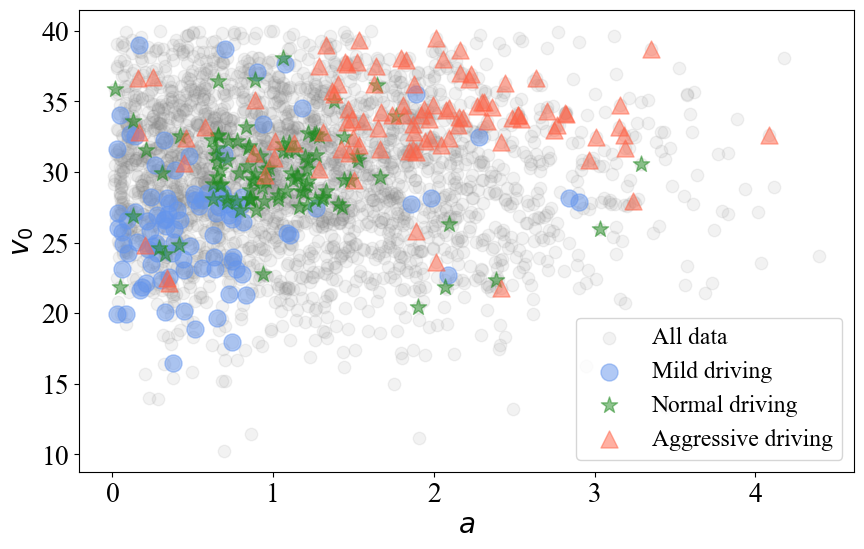

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

font_family = 'Times new roman'
font_size = 18
plt.rcParams['font.family'] = font_family

# Plot all data points
plt.scatter(df['a'], df['v0'], color='grey', alpha=0.1, label='All data', s=80)

# Highlight the selected groups
plt.scatter(df[df['label'] == -1]['a'], df[df['label'] == -1]['v0'], color='cornflowerblue', alpha=0.5, label='Mild driving', s=150, marker='o')
plt.scatter(df[df['label'] == 0]['a'], df[df['label'] == 0]['v0'], color='forestgreen', alpha=0.5, label='Normal driving', s=150, marker='*')
plt.scatter(df[df['label'] == 1]['a'], df[df['label'] == 1]['v0'], color='tomato', alpha=0.5, label='Aggressive driving', s=150, marker='^')

# Add titles and labels
# plt.title('Visualization of All Data with Highlighted Groups')
plt.xlabel('$a$', fontsize=font_size+2)
plt.ylabel('$v_0$', fontsize=font_size+2)
plt.tick_params(axis='both', which='major', labelsize=font_size+2)
# Set the legend with customized font properties
plt.legend(fontsize=font_size-1)
# plt.title('Visualization of mannualy labelling')
plt.savefig('Highd_IDM_Label_va.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()


In [72]:
label_0_count = (df['label'] == -1).sum()

print("Number of rows where label is 0:", label_0_count)

Number of rows where label is 0: 426


In [17]:
import numpy as np

# Assuming data_array is your loaded data with shape (1097, 6)
gap = data[:, 3]
desired_speed = data[:, 0]

# Calculate percentiles for thresholds
high_accel_threshold = np.percentile(gap, 75)
low_accel_threshold = np.percentile(gap, 25)
middle1_accel_threshold = np.percentile(gap, 65)
middle2_accel_threshold = np.percentile(gap, 35)

high_speed_threshold = np.percentile(desired_speed, 75)
low_speed_threshold = np.percentile(desired_speed, 25)
middle1_speed_threshold = np.percentile(desired_speed, 65)
middle2_speed_threshold = np.percentile(desired_speed, 35)

# Label drivers
labels = []
aggressive_drivers = []
mild_drivers = []
normal_drivers = []

for idx, (accel, speed) in enumerate(zip(gap, desired_speed)):
    if accel > high_accel_threshold and speed > high_speed_threshold:
        labels.append("Aggressive")
        aggressive_drivers.append(idx + 1)
    elif accel < low_accel_threshold and speed < low_speed_threshold:
        labels.append("Mild")
        mild_drivers.append(idx + 1)
    elif middle2_accel_threshold < accel < middle1_accel_threshold and middle2_speed_threshold < speed < middle1_speed_threshold:
        labels.append("Normal")
        normal_drivers.append(idx + 1)
    else:
        labels.append("Uncategorized")

labels = np.array(labels)

print("Labels assigned:", len(labels))
print("Number of Aggressive drivers:", len(aggressive_drivers))
print("Number of Mild drivers:", len(mild_drivers))
print("Number of Normal drivers:", len(normal_drivers))
print("Number of Uncategorized drivers:", np.sum(labels == "Uncategorized"))

print("\nAggressive Driver IDs:", aggressive_drivers)
print("Mild Driver IDs:", mild_drivers)
print("Normal Driver IDs:", normal_drivers)


Labels assigned: 2000
Number of Aggressive drivers: 138
Number of Mild drivers: 141
Number of Normal drivers: 175
Number of Uncategorized drivers: 1546

Aggressive Driver IDs: [16, 27, 51, 54, 57, 72, 78, 85, 124, 129, 148, 158, 185, 187, 188, 196, 211, 219, 225, 226, 240, 248, 249, 263, 267, 268, 277, 288, 293, 296, 309, 310, 370, 381, 403, 437, 444, 485, 502, 520, 543, 567, 573, 598, 602, 604, 609, 610, 611, 612, 620, 641, 676, 679, 686, 733, 754, 766, 767, 779, 796, 827, 868, 892, 925, 940, 941, 975, 994, 1007, 1029, 1042, 1054, 1059, 1068, 1081, 1094, 1119, 1126, 1131, 1159, 1161, 1187, 1205, 1212, 1235, 1248, 1251, 1312, 1331, 1344, 1350, 1357, 1381, 1392, 1398, 1413, 1419, 1432, 1434, 1445, 1451, 1476, 1488, 1491, 1498, 1519, 1521, 1530, 1581, 1591, 1624, 1632, 1636, 1643, 1684, 1703, 1714, 1719, 1727, 1736, 1738, 1739, 1748, 1753, 1764, 1767, 1780, 1782, 1789, 1861, 1891, 1904, 1967, 1976, 1993, 1994, 1999]
Mild Driver IDs: [76, 100, 132, 137, 142, 157, 171, 174, 180, 194, 230, 

In [ ]:
df = pd.read_csv('IDM_cali_params_list.csv')
data = np.array(df)


# Create a dictionary for mapping the labels
label_mapping = {
    "Aggressive": 1,
    "Normal": 0,
    "Mild": -1,
    "Uncategorized": np.nan  # Using NaN for the 'Uncategorized' label
}

# Map the labels
numeric_labels = np.array([label_mapping[label] for label in labels])

# Add the numeric_labels as a new column to the data_array
data_with_labels = np.column_stack((data, numeric_labels))

print(data_with_labels)


[[45.80660541  2.62352234  2.35666301  4.87883097  2.58912058         nan]
 [36.76758387  2.560798    3.12461596  2.54266849  1.93754113         nan]
 [23.00885546  2.81455472  2.32979163  3.96220507  1.62367422         nan]
 ...
 [38.32566618  0.84910805  3.73382214  5.66995373  1.8060142          nan]
 [43.45861588  2.78704445  0.53179413  5.78583645  0.62917277  1.        ]
 [19.0491907   3.869737    2.08290901  1.9083006   1.2801612  -1.        ]]


In [ ]:
np.savetxt("para_with_labels_np.csv", data_with_labels, delimiter=",")
columns = ["v0", "a", "b", "s0", "T", "label"]  # Adjust column names as needed
df = pd.DataFrame(data_with_labels, columns=columns)
# Save the DataFrame to a CSV
df.to_csv("para_with_labels_pd.csv", index=False)
